# 4.3.5-hgWGCNA modules in space

**Inés Sentís**

Plot modules as signatues in tissue

In [1]:
from pyprojroot import here
here = str(here())
import sys, os
sys.path.append(os.path.join(here,"utils"))

In [2]:
# basic pkgs
import os
import pandas as pd
import numpy as np
import glob

# analysis pkgs
import scanpy as sc
import anndata as ad
import scipy as sp
import decoupler as dc
import gseapy as gp

# plotting pkgs
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# own modules
from paths import *
from module import run_magic
from variables import resolutions, colors_donors

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', -1)

%load_ext autoreload
%autoreload 2
%config IPCompleter.greedy=True

/mnt/temp/isentis/slurm_6859496/ipykernel_1553094/307271672.py:26: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


In [3]:
def config_rcparams():
    commonFontsize = 12
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['font.size'] = commonFontsize
    plt.rcParams['axes.labelsize'] = commonFontsize
    plt.rcParams['xtick.labelsize'] = commonFontsize
    plt.rcParams['ytick.labelsize'] = commonFontsize
    plt.rcParams['axes.titlesize'] = 14
    # plt.rcParams['text'] = commonFontsize
    plt.rcParams['svg.fonttype'] = 'none'
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.cal'] = 'DejaVu Sans'
    plt.rcParams['mathtext.rm'] = 'DejaVu Sans'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.linewidth'] = 0.7
    plt.rcParams['xtick.major.width'] = 0.7
    plt.rcParams['ytick.major.width'] = 0.7
    plt.rcParams['xtick.major.size'] = 3
    plt.rcParams['ytick.major.size'] = 3
    


config_rcparams()    

In [4]:
sc.logging.print_versions()
sc.set_figure_params(facecolor="white", figsize=(8, 8), 
                     scanpy=True, fontsize=16)
path_to_figures = os.path.join(here, "AVGUSTINOVA_01_06_09_15", "4-annotation", version, "plots_"+version)
sc.settings.figdir = path_to_figures
sc.settings.verbosity = 3

-----
anndata     0.9.2
scanpy      1.9.5
-----
NaiveDE                     NA
PIL                         10.0.0
SpatialDE                   NA
anyio                       NA
arrow                       1.2.3
asttokens                   NA
attr                        23.1.0
attrs                       23.1.0
babel                       2.12.1
backcall                    0.2.0
brotli                      1.1.0
certifi                     2023.07.22
cffi                        1.14.6
charset_normalizer          3.2.0
comm                        0.1.4
cycler                      0.10.0
cython_runtime              NA
dateutil                    2.8.2
debugpy                     1.8.0
decorator                   5.1.1
decoupler                   1.5.0
defusedxml                  0.7.1
deprecated                  1.2.14
exceptiongroup              1.1.3
executing                   1.2.0
fastjsonschema              NA
fqdn                        NA
future                      0.18.3
graphtoo

## Load data

In [5]:
df_info = pd.read_csv(os.path.join(here, "utils/info_samples.csv"))
df_info = df_info[(df_info["modality"] == "st") & (~df_info["quality"].isin(["Bad", "NM"]))]
#df_info = df_info[df_info["patient"] != "p11"]

In [6]:
dict_samples = dict()

for sample in df_info['patient']:
    
    batch = df_info[df_info['patient'] == sample].reset_index()["subproject"][0]
    exec(open(os.path.join(here, batch,"st_analysis/misc/paths.py")).read())
    path_to_data = os.path.join(here, batch, "st_analysis/3-clustering", version, "py_objects_"+version)
    
    # read object
    adata = sc.read_h5ad(os.path.join(path_to_data, sample+'.h5ad'))
    adata.obs["patient"] = sample

    dict_samples[sample] = adata

In [7]:
modules = pd.read_csv(os.path.join(here,"AVGUSTINOVA_02_to_30/5-modules/Tumor_modules.tsv"),sep="\t")
modules["module"] = modules["module"].apply(lambda x: x.replace("Tumor", "M"))
modules.head()

,gene_name,module,kME
0,PTMA,M_1,0.614277
1,HSP90AB1,M_1,0.609044
2,GAPDH,M_1,0.598630
3,RACK1,M_1,0.595748
4,EEF1G,M_1,0.594276


## Run Modules all together

In [8]:
# Merge the AnnData objects
merged_adata = ad.concat(dict_samples.values(), join='outer')

# remove empty genes
sc.pp.filter_genes(merged_adata, min_cells=1)

# Normalize the merged AnnData object
merged_adata.X = merged_adata.layers['counts'].copy()
sc.pp.normalize_total(merged_adata, target_sum=1e4)
sc.pp.log1p(merged_adata)
merged_adata.layers['normalized'] = merged_adata.X.copy()

filtered out 12 genes that are detected in less than 1 cells
normalizing counts per cell
    finished (0:00:00)


In [9]:
dc.run_mlm(mat=merged_adata, net=modules, source='module', target='gene_name', weight='kME', verbose=True)
    
merged_adata.obsm['mod_mlm_estimate'] = merged_adata.obsm['mlm_estimate'].copy()
merged_adata.obsm['mod_mlm_pvals'] = merged_adata.obsm['mlm_pvals'].copy()

12 features of mat are empty, they will be removed.
Running mlm on mat with 21534 samples and 28662 targets for 19 sources.


100%|██████████| 3/3 [00:21<00:00,  7.22s/it]


In [10]:
df_plot = merged_adata.obsm['mod_mlm_estimate']
df_plot = pd.merge(df_plot, merged_adata.obs[["patient"]],
                  left_index=True, right_index=True)
colors = df_plot['patient'].map(colors_donors)

In [11]:
for p,ann in dict_samples.items():
    df_tmp = df_plot[df_plot["patient"] == p]
    cols = list(merged_adata.obsm['mod_mlm_estimate'].columns)
    df_tmp[[c + '_z' for c in cols]] = (df_tmp[cols] - df_tmp[cols].mean()) / df_tmp[cols].std()
    cols.extend([c + '_z' for c in cols])
    ann.obs = pd.merge(ann.obs, df_tmp[cols], 
                      how='left', left_index = True, right_index=True)

/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/pandas/core/frame.py:3191: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self[k1] = value[k2]


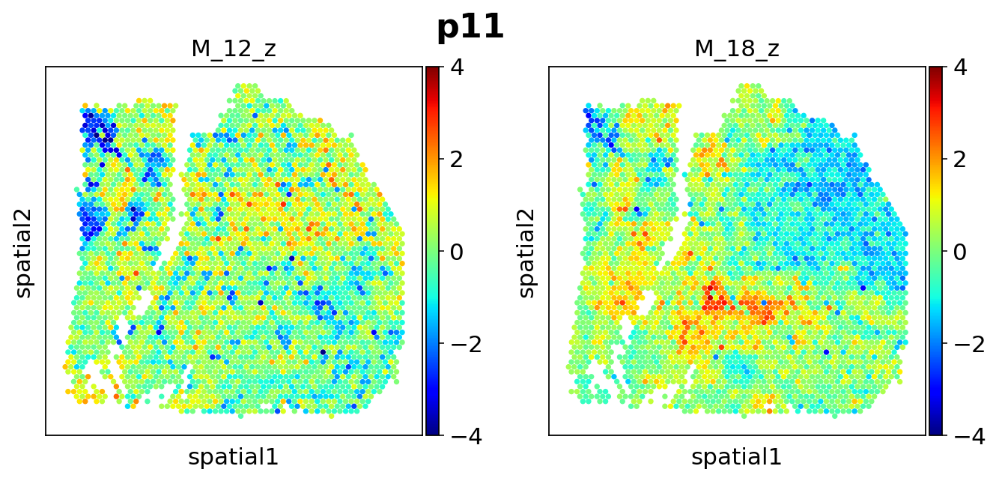

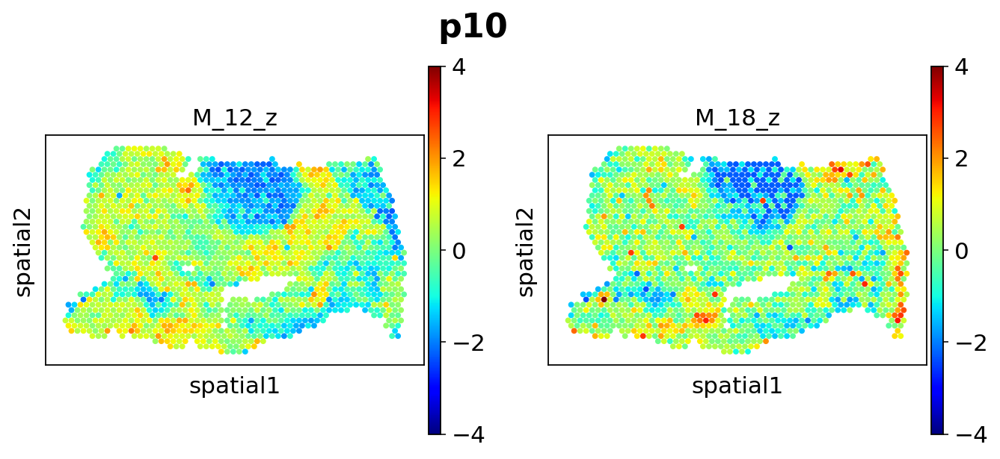

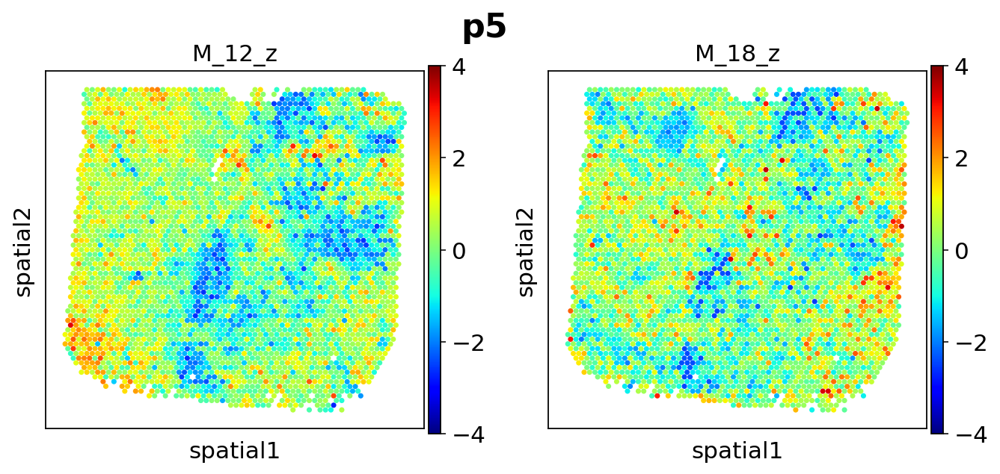

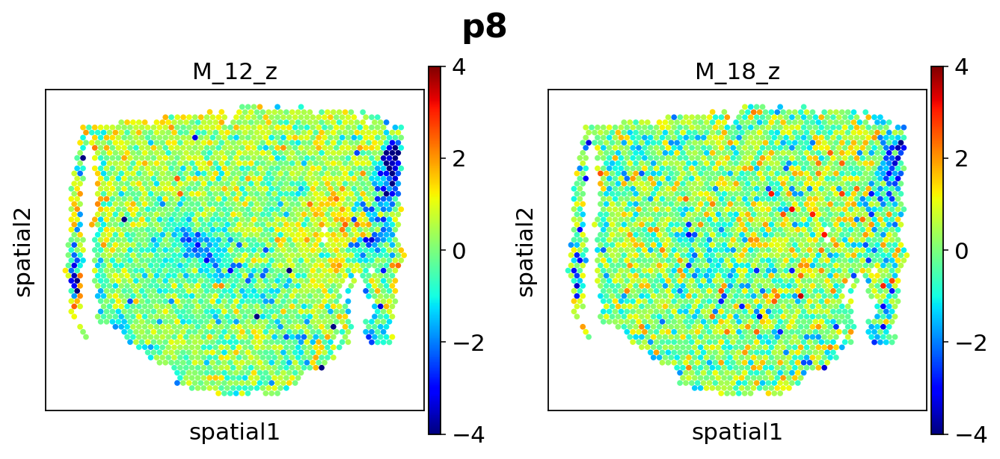

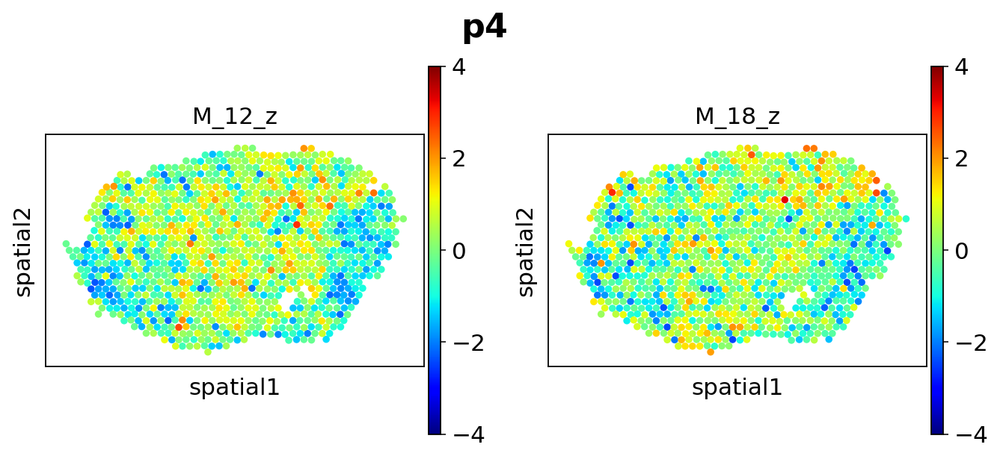

...

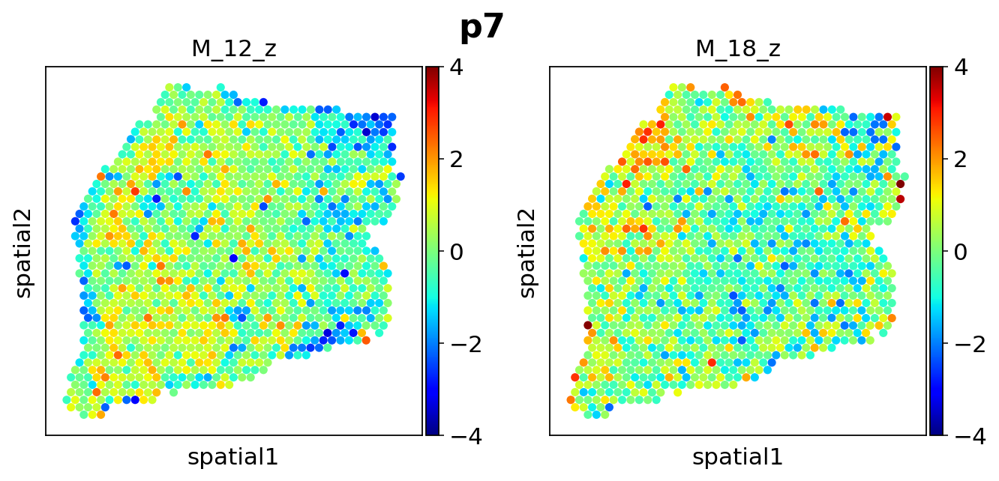

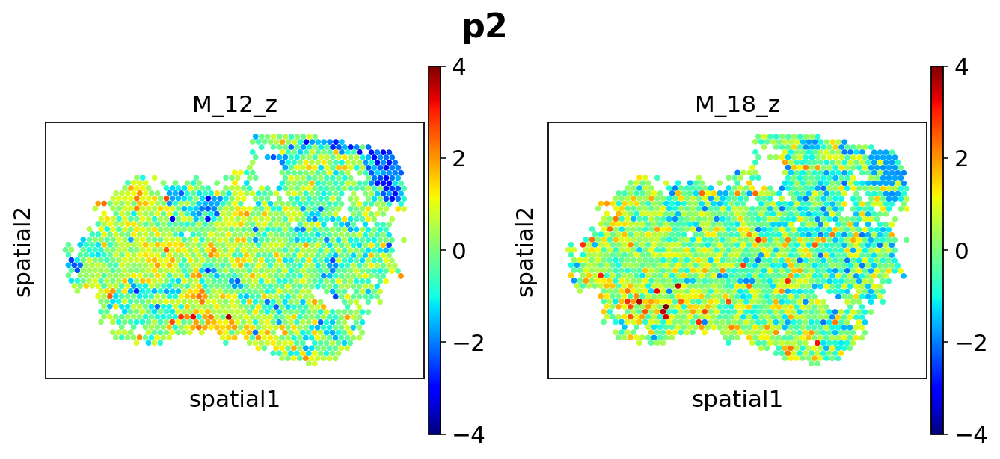

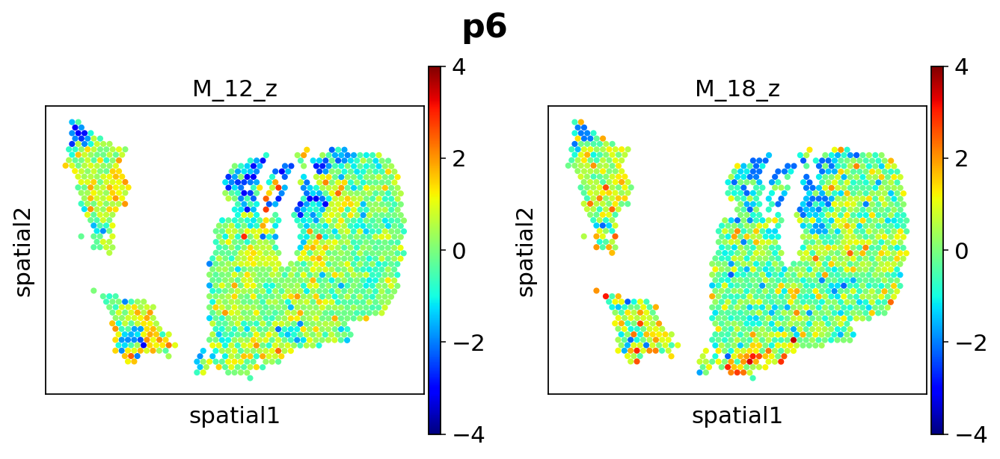

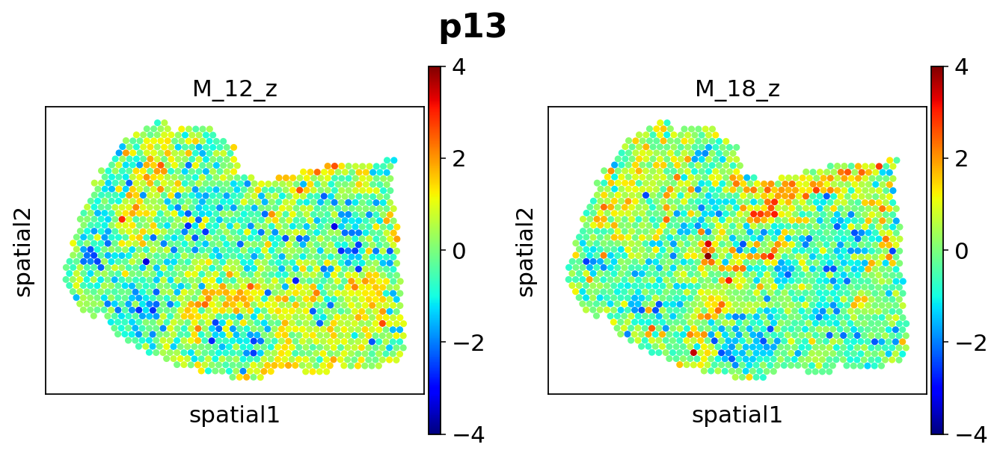

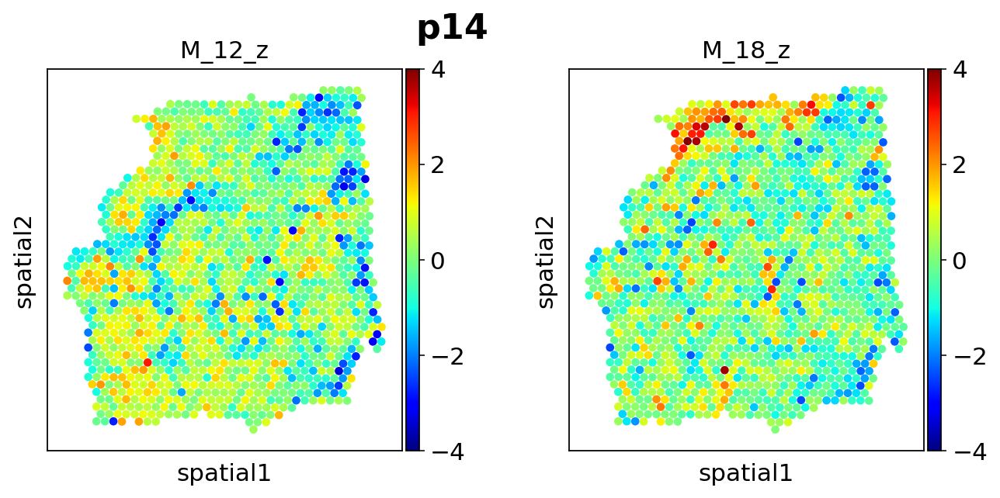

In [12]:
plt.rcParams["figure.figsize"] = (5,3)
sc.set_figure_params(fontsize=14)
for id, ann in dict_samples.items():
#    if id=="p11":
#        pass
#    else:
    sc.pl.spatial(ann, color=["M_12_z","M_18_z"], 
                  cmap='jet', ncols=2,vmin=-4,vmax=4, size=1.5, 
                  img_key=None, show=False)
    
    plt.suptitle(id, fontsize=20,ha="right",va="center",fontweight="bold")  
    plt.savefig(os.path.join(path_to_figures,"4.3.5-Tissue_"+id+".svg"), format='svg', bbox_inches='tight', dpi=300) 
    plt.show()

Calculating MAGIC...
  Running MAGIC on 1728 cells and 22811 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.80 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.10 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 3.04 seconds.
  Calculating imputation...
  Calculated imputation in 0.04 seconds.
Calculated MAGIC in 3.24 seconds.


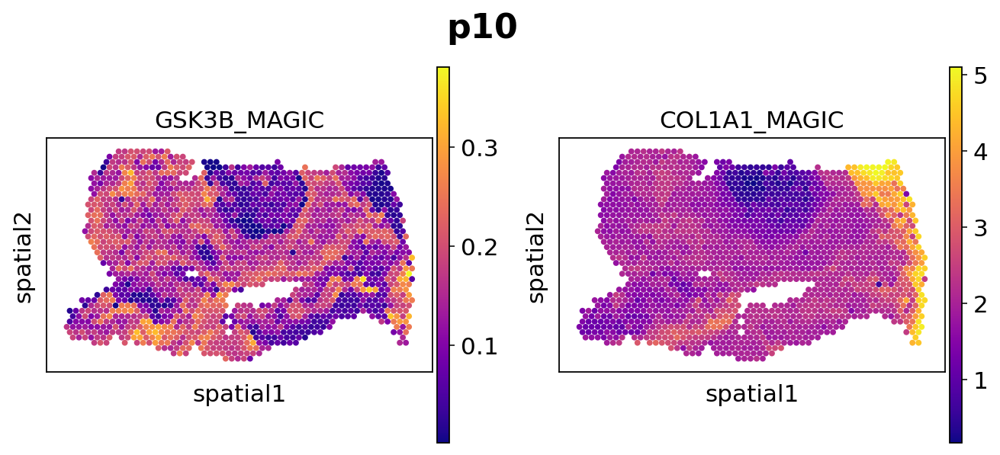

Calculating MAGIC...
  Running MAGIC on 3871 cells and 22249 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 4.34 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.40 seconds.
    Calculating affinities...
    Calculated affinities in 0.38 seconds.
  Calculated graph and diffusion operator in 5.24 seconds.
  Calculating imputation...
Calculated MAGIC in 5.47 seconds.


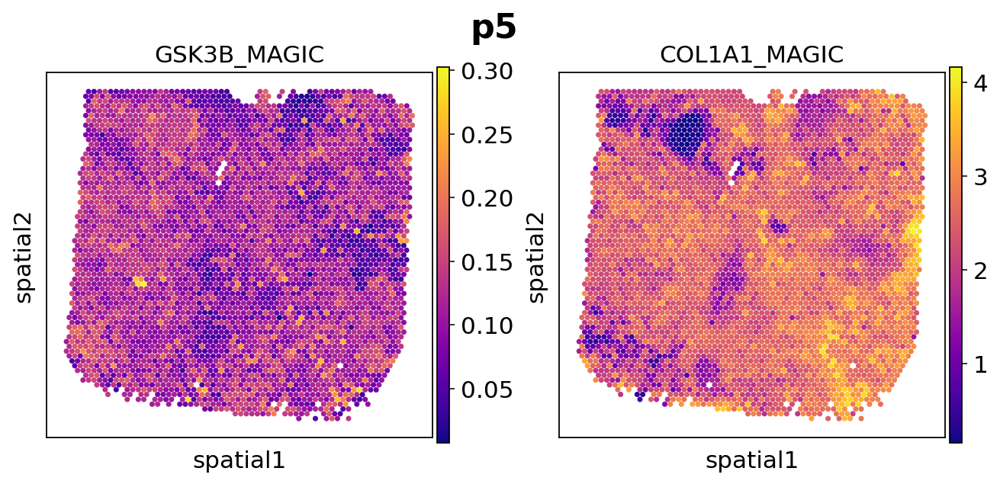

Calculating MAGIC...
  Running MAGIC on 2584 cells and 23332 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.33 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.23 seconds.
    Calculating affinities...
    Calculated affinities in 0.21 seconds.
  Calculated graph and diffusion operator in 3.85 seconds.
  Calculating imputation...
Calculated MAGIC in 4.05 seconds.


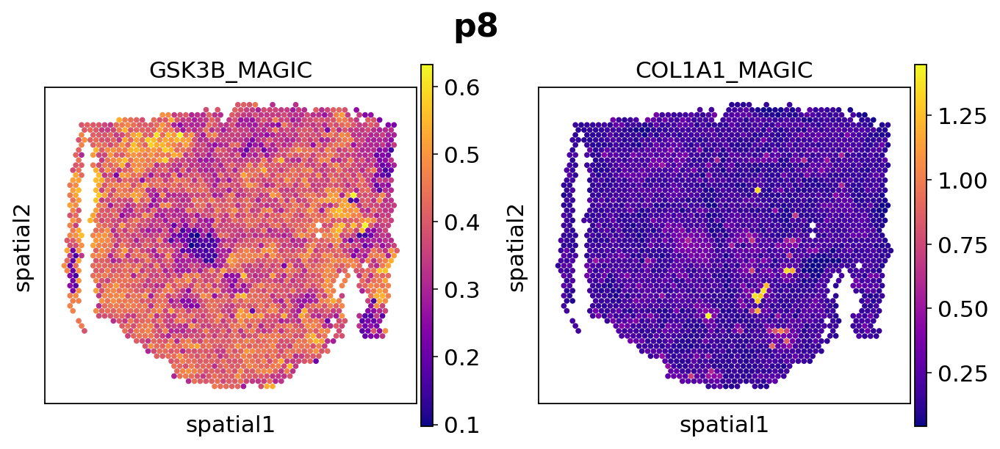

Calculating MAGIC...
  Running MAGIC on 1097 cells and 19648 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.57 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.05 seconds.
  Calculated graph and diffusion operator in 1.73 seconds.
  Calculating imputation...
Calculated MAGIC in 1.85 seconds.


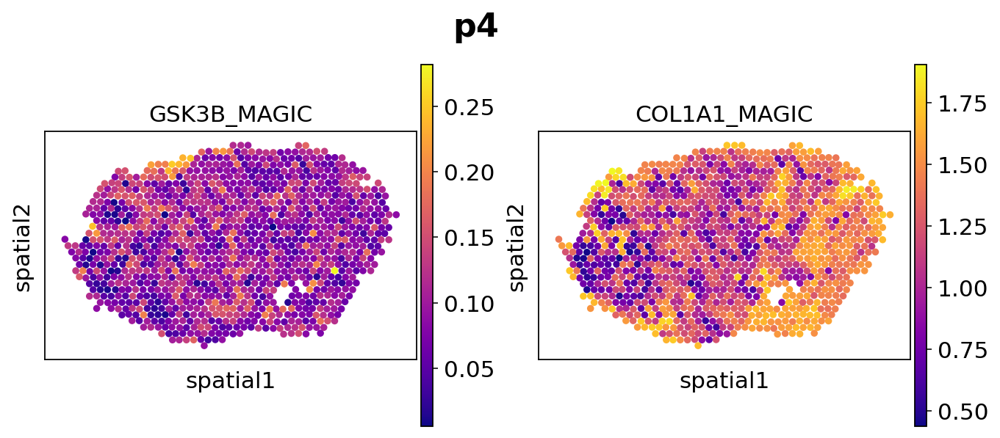

Calculating MAGIC...
  Running MAGIC on 1925 cells and 18351 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.41 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.14 seconds.
    Calculating affinities...
    Calculated affinities in 0.12 seconds.
  Calculated graph and diffusion operator in 2.72 seconds.
  Calculating imputation...
Calculated MAGIC in 2.87 seconds.


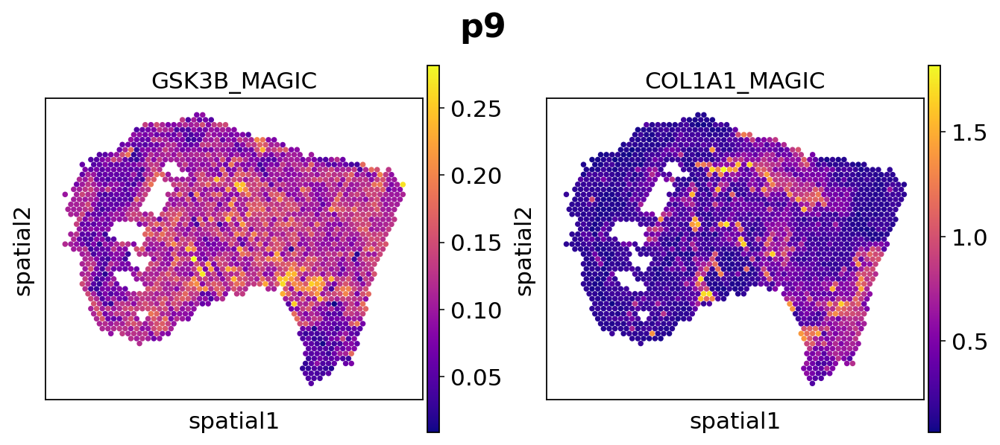

Calculating MAGIC...
  Running MAGIC on 1296 cells and 19412 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 1.81 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 1.97 seconds.
  Calculating imputation...
Calculated MAGIC in 2.10 seconds.


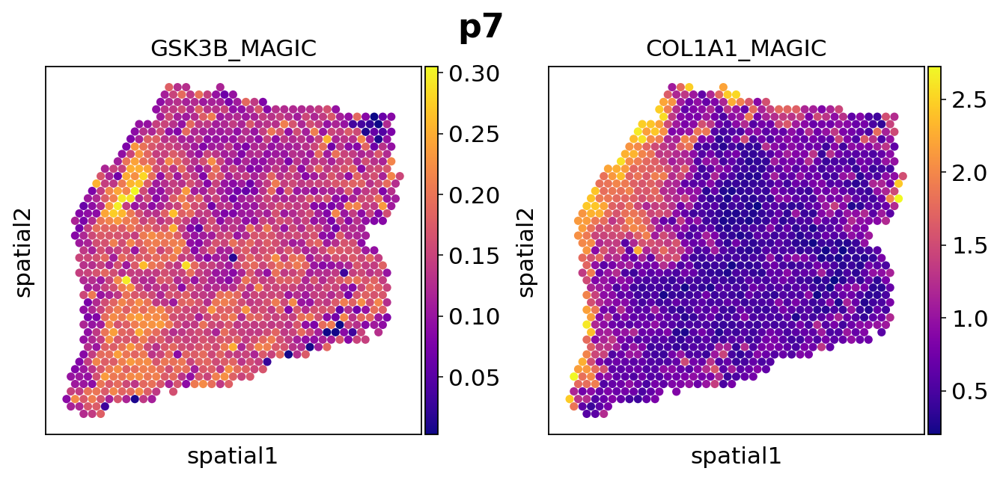

Calculating MAGIC...
  Running MAGIC on 1697 cells and 20808 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 2.41 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.11 seconds.
    Calculating affinities...
    Calculated affinities in 0.09 seconds.
  Calculated graph and diffusion operator in 2.65 seconds.
  Calculating imputation...
Calculated MAGIC in 2.80 seconds.


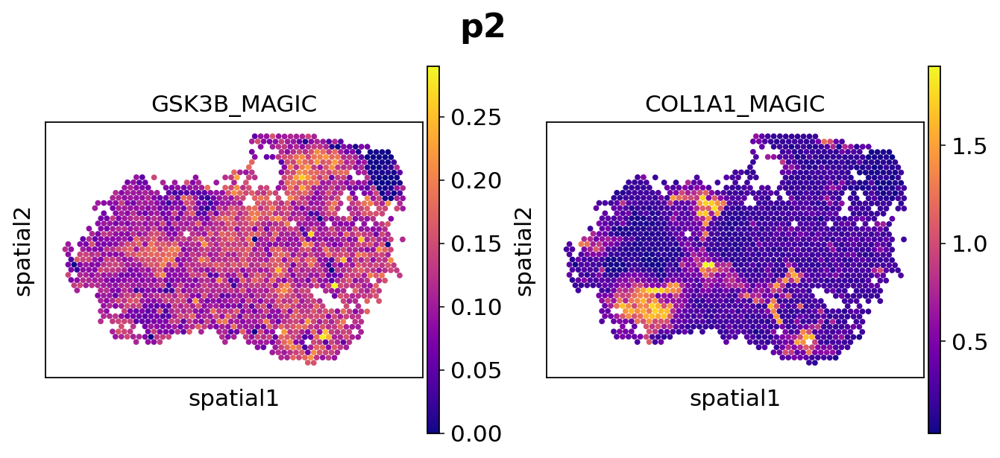

Calculating MAGIC...
  Running MAGIC on 1205 cells and 19209 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 1.72 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.05 seconds.
  Calculated graph and diffusion operator in 1.86 seconds.
  Calculating imputation...
Calculated MAGIC in 2.00 seconds.


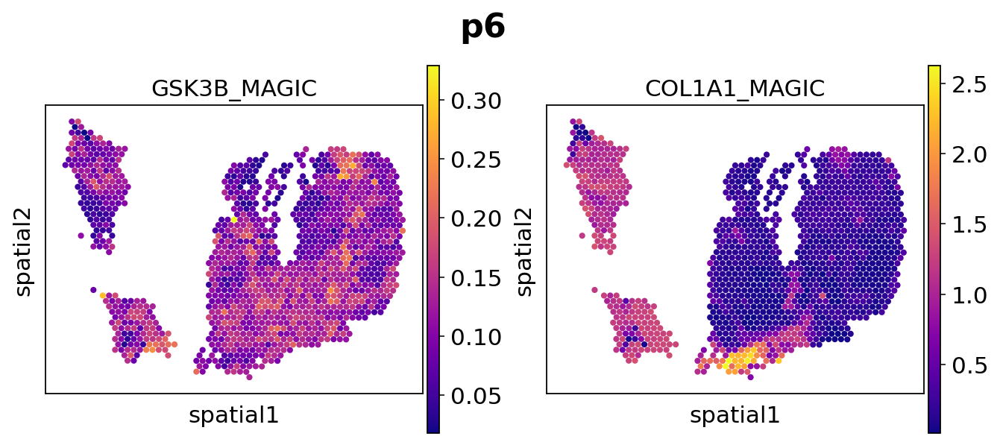

Calculating MAGIC...
  Running MAGIC on 1581 cells and 21213 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.38 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.10 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 2.61 seconds.
  Calculating imputation...
Calculated MAGIC in 2.77 seconds.


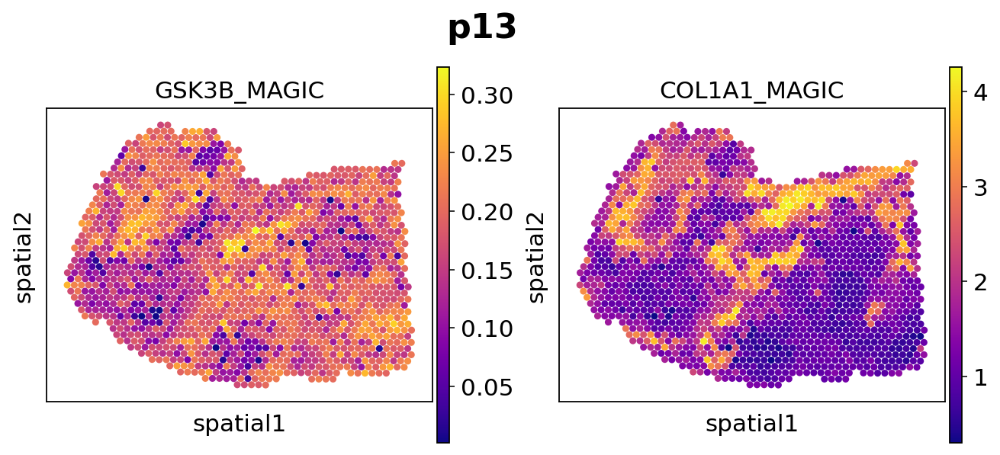

Calculating MAGIC...
  Running MAGIC on 1352 cells and 21374 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.10 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 2.28 seconds.
  Calculating imputation...
Calculated MAGIC in 2.43 seconds.


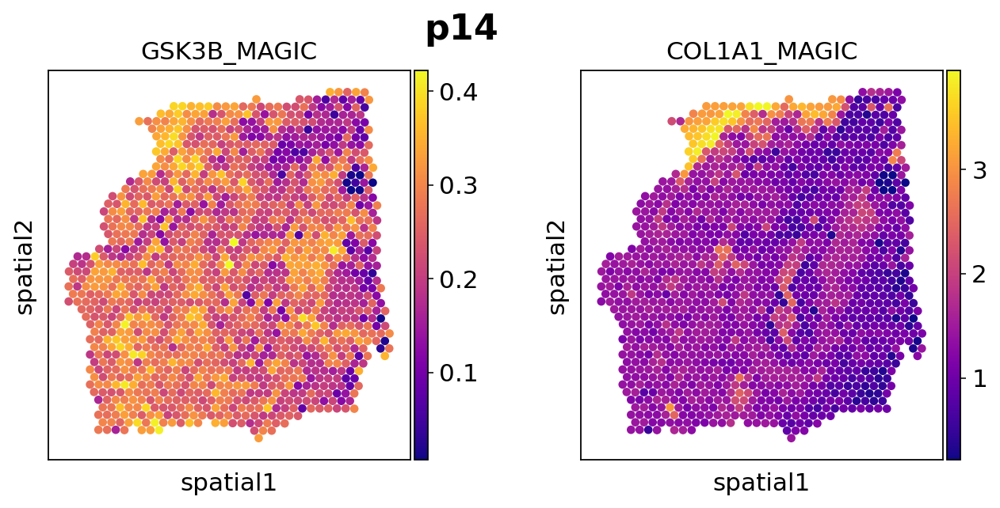

In [13]:
for id, ann in dict_samples.items():
    if id not in ["p11"]:
        ann.obs = ann.obs[ann.obs.columns.drop(list(ann.obs.filter(regex='_MAGIC')))]
        ann = run_magic(ann, ["GSK3B","COL1A1"])
        sc.pl.spatial(ann, color=["GSK3B_MAGIC","COL1A1_MAGIC"], 
                      cmap='plasma', show=False, size=1.5, img_key=None)
        
        plt.suptitle(id, fontsize=20,ha="right",va="center",fontweight="bold") 
        plt.savefig(os.path.join(path_to_figures,"4.3.5-Markers_"+id+".svg"), format='svg', bbox_inches='tight', dpi=300)
        plt.show()
    else:
        pass